<a href="https://colab.research.google.com/github/Dhenielc15/MOTORENTO_CANDIDATE_EXAM/blob/main/museum_membership_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Museum Membership Analyst Exercise — June 2026
**Repeatable pipeline: incentive calculation → data controls → investigation**

## How to run in Google Colab
1. Open [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook** → choose `museum_membership_analysis.ipynb`.
2. Click the **folder icon** in the left sidebar (Files) → click the **Upload** icon (page with an up arrow) → choose `museum_analyst_dataset.xlsx`.
   The dataset must sit in the main `/content` folder, **not** inside `sample_data`. Drag it to the same level as `sample_data` if needed. The file name must match `FILE` in the config cell (default: `museum_analyst_dataset.xlsx`).
3. Click **Runtime → Run all** (or `Ctrl+F9`). If a cell fails, use **Runtime → Restart session and run all**.
4. Results appear in the folder `/content/outputs/`: `payout_2026-06.xlsx` (summary, payout table, exception register, reconciliation) and `outputs/charts/` (every chart as a PNG). Download them with the Files sidebar (right-click → Download), or run the optional download cell at the end of this notebook.
5. Colab deletes files when the session disconnects, so download your results before closing.

Alternative upload (no sidebar): run this in a cell before the config cell, then pick the file when prompted.
```python
from google.colab import files
uploaded = files.upload()   # choose museum_analyst_dataset.xlsx
```

Optional download cell for the end of the notebook:
```python
import shutil
from google.colab import files
shutil.make_archive("outputs_" + PERIOD, "zip", "outputs")
files.download("outputs_" + PERIOD + ".zip")
```

Running locally with Jupyter works the same way: keep the notebook and the xlsx in the same folder, then **Kernel → Restart & Run All**.

**How to refresh next month:** replace `museum_analyst_dataset.xlsx` with the new file (same two sheets: `Transactions`, `Admissions`, same columns), then **Runtime → Run all** (Colab) or **Kernel → Restart & Run All** (Jupyter). Everything (period, associates, exceptions, payout, charts) is derived from the file. Only the policy parameters in the config cell are typed in.

**Sections**
1. Config & load
2. Data controls → exception register
3. Incentive calculation → payout table
4. Reconciliation
5. Export to Excel
6. Investigation
7. Final self-checks
8. Final summary table

**Assumptions (stated explicitly because the brief leaves them open)**
- "Net eligible NEW sales ≥ 25" is a **count of sales**, not credits (25 credits is smaller than a single sale).
- Eligible = SALE, COMPLETED, channel DESK, not held. ONLINE sales earn nothing and do not count to the bonus.
- A **held** row earns/reverses nothing and stays on the exception register. A refund that references a held or ambiguous sale is itself held.
- Refund reversal = the *already rounded* incentive of the original sale (so a reversal always cancels it exactly), charged to the original seller.
- Refund of an ONLINE sale → reversal 0 (the original earned 0).
- The bonus is evaluated on net NEW count (valid refunds of eligible NEW sales are subtracted), and the floor `max(0, ...)` is applied per associate.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
CHART_DIR = Path("outputs") / "charts"; CHART_DIR.mkdir(parents=True, exist_ok=True)
_orig_show = plt.show
def _show_and_save(*a, **k):                       # every chart is also saved as its own PNG (named after its title)
    ax0 = plt.gcf().axes[0]
    title = ax0.get_title() or ax0.get_title(loc="left") or "chart"
    plt.gcf().savefig(CHART_DIR / (re.sub(r"[^A-Za-z0-9]+", "_", title)[:70].strip("_") + ".png"), dpi=130, bbox_inches="tight")
    _orig_show(*a, **k)
plt.show = _show_and_save

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 120)
sns.set_theme(style="whitegrid")

# ---------- CONFIG (the only place to edit) ----------
FILE    = "museum_analyst_dataset.xlsx"
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
PERIOD  = None                       # e.g. "2026-06"; None = infer the most common month in the file

NEW_RATES    = {"Single": "0.08", "Duo": "0.10", "Circle": "0.12"}   # strings -> exact Decimal maths
RENEWAL_RATE = "0.03"
BONUS_AMOUNT, BONUS_MIN_NEW = 75, 25

ALLOWED = {
    "event_type": {"SALE", "REFUND"},
    "sale_kind":  {"NEW", "RENEWAL"},
    "product":    set(NEW_RATES),
    "channel":    {"DESK", "ONLINE"},
    "status":     {"COMPLETED", "PENDING", "VOID"},
}
KNOWN_OFFERS = {"OPEN-DAY", "MIDYEAR-CIRCLE"}                     # unknown offer = warning, price check still applies
LIST_PRICE   = {"Single": 120, "Duo": 200, "Circle": 300}
DISCOUNTS    = (0.85, 0.75)                                        # allowed discounted prices = list * 0.85 / 0.75
MIN_N        = 20                                                  # min sales in a cell for the investigation ranking
REQUIRED     = ["transaction_id", "date", "venue", "associate_id", "event_type",
                "sale_kind", "product", "channel", "status", "amount_credits"]

## 1. Load

In [2]:
raw = pd.read_excel(FILE, sheet_name="Transactions", dtype=str)
adm = pd.read_excel(FILE, sheet_name="Admissions")
raw.columns = raw.columns.str.strip()

def prepare(raw_df):
    t = raw_df.copy()
    t.columns = t.columns.str.strip()
    for c in t.columns:
        t[c] = t[c].str.strip()
    t = t.replace({"": np.nan})
    t["src_row"]     = t.index + 2                                   # Excel row number for traceability
    t["amount_num"]  = pd.to_numeric(t["amount_credits"], errors="coerce")
    t["date_parsed"] = pd.to_datetime(t["date"], format="%Y-%m-%d", errors="coerce")
    return t

tx = prepare(raw)
adm["date"] = adm["date"].astype(str)

if PERIOD is None:
    PERIOD = tx["date_parsed"].dt.strftime("%Y-%m").mode().iloc[0]
KNOWN_VENUES = set(adm["venue"].dropna().str.strip())

print(f"Period: {PERIOD} | rows: {len(tx):,} | associates: {tx.associate_id.nunique()} | venues: {sorted(KNOWN_VENUES)}")
display(tx.head())

Period: 2026-06 | rows: 2,121 | associates: 48 | venues: ['Clock Hall', 'Garden Wing', 'North Gallery', 'River Annex']


,transaction_id,date,venue,associate_id,event_type,sale_kind,product,channel,status,amount_credits,original_transaction_id,offer_code,src_row,amount_num,date_parsed
0,T00001,2026-06-01,North Gallery,A011,SALE,NEW,Duo,DESK,COMPLETED,200,NaN,NaN,2,200,2026-06-01
1,T00002,2026-06-01,North Gallery,A008,SALE,NEW,Single,ONLINE,COMPLETED,120,NaN,NaN,3,120,2026-06-01
2,T00003,2026-06-01,North Gallery,A004,SALE,NEW,Duo,DESK,COMPLETED,200,NaN,NaN,4,200,2026-06-01
3,T00004,2026-06-01,North Gallery,A002,SALE,NEW,Single,DESK,COMPLETED,102,NaN,OPEN-DAY,5,102,2026-06-01
4,T00005,2026-06-01,North Gallery,A001,SALE,NEW,Circle,DESK,COMPLETED,300,NaN,NaN,6,300,2026-06-01


## 2. Data controls → exception register
Two severities:
- **HOLD** – payout would be unreliable, so the row earns / reverses **nothing** and is listed for review.
- **WARN** – visible on the register, but payout is unaffected.

All checks are vectorised over the full file (no row-by-row checking).

In [3]:
def run_controls(tx):
    """All data controls, vectorised over the full file. Returns tx + hold/warn columns, HOLD and WARN flag matrices."""
    tx = tx.copy()
    is_sale   = tx.event_type.eq("SALE")
    is_refund = tx.event_type.eq("REFUND")
    id_rows   = tx.groupby("transaction_id")["transaction_id"].transform("size")

    # ---- Row-level HOLD checks -------------------------------------------------
    H = pd.DataFrame(index=tx.index)
    H["DUPLICATE_ID"] = id_rows.gt(1)                                              # hold EVERY row of the ID

    miss = tx[REQUIRED].isna().any(axis=1) | (is_refund & tx.original_transaction_id.isna())
    H["MISSING_FIELD"] = miss

    bad_cat = pd.Series(False, index=tx.index)
    for col, ok in ALLOWED.items():
        bad_cat |= tx[col].notna() & ~tx[col].isin(ok)
    bad_cat |= tx.venue.notna() & ~tx.venue.isin(KNOWN_VENUES)
    bad_cat |= tx.associate_id.notna() & ~tx.associate_id.str.match(r"^A\d{3}$", na=False)
    H["UNEXPECTED_CATEGORY"] = bad_cat

    H["BAD_DATE"]   = tx.date.notna() & (tx.date_parsed.isna() | (tx.date_parsed.dt.strftime("%Y-%m") != PERIOD))
    H["BAD_AMOUNT"] = tx.amount_credits.notna() & (tx.amount_num.isna() | (tx.amount_num <= 0))
    H["SALE_HAS_ORIGINAL_ID"] = is_sale & tx.original_transaction_id.notna()

    # price integrity: no offer -> list price; offer -> one of the discounted prices
    lp = tx["product"].map(LIST_PRICE)
    ok_disc = pd.concat([(lp * d).round() for d in DISCOUNTS], axis=1).eq(tx.amount_num, axis=0).any(axis=1)
    price_ok = np.where(tx.offer_code.isna(), tx.amount_num.eq(lp), ok_disc)
    H["PRICE_MISMATCH"] = is_sale & lp.notna() & tx.amount_num.notna() & ~pd.Series(price_ok, index=tx.index)

    row_hold = H.any(axis=1)

    # ---- Refund-link HOLD checks (completed refunds only) ----------------------
    cref = is_refund & tx.status.eq("COMPLETED") & tx.original_transaction_id.notna()
    orig = tx.original_transaction_id
    n_with_id = orig.map(tx.groupby("transaction_id").size()).fillna(0)

    sale_u = tx[is_sale & id_rows.eq(1)].set_index("transaction_id")                # unique sales only
    found  = orig.isin(sale_u.index)
    held_sale_ids = set(tx.loc[is_sale & row_hold, "transaction_id"])

    def from_orig(col):
        return orig.map(sale_u[col]) if len(sale_u) else pd.Series(np.nan, index=tx.index)

    o_status, o_prod, o_amt = from_orig("status"), from_orig("product"), from_orig("amount_num")
    o_date  = pd.to_datetime(from_orig("date"), format="%Y-%m-%d", errors="coerce")
    o_venue, o_chan, o_kind = from_orig("venue"), from_orig("channel"), from_orig("sale_kind")

    R = pd.DataFrame(index=tx.index)
    R["REFUND_ORIG_NOT_FOUND"]     = cref & ~found & n_with_id.le(1)
    R["REFUND_ORIG_NOT_UNIQUE"]    = cref & n_with_id.gt(1)
    R["REFUND_ORIG_NOT_COMPLETED"] = cref & found & o_status.ne("COMPLETED")
    R["REFUND_PRODUCT_MISMATCH"]   = cref & found & o_prod.ne(tx["product"])
    R["REFUND_AMOUNT_MISMATCH"]    = cref & found & o_amt.ne(tx["amount_num"])
    R["REFUND_ORIG_HELD"]          = cref & orig.isin(held_sale_ids)
    R["REFUND_BEFORE_SALE"]        = cref & found & tx.date_parsed.lt(o_date)
    dup_ref = tx[cref].duplicated("original_transaction_id", keep=False)
    R["REFUND_DUPLICATE_FOR_SALE"] = cref & dup_ref.reindex(tx.index, fill_value=False)

    # ---- WARN (informational) ---------------------------------------------------
    W = pd.DataFrame(index=tx.index)
    W["UNKNOWN_OFFER"]            = tx.offer_code.notna() & ~tx.offer_code.isin(KNOWN_OFFERS)
    W["REFUND_VENUE_DIFFERS"]     = cref & found & o_venue.ne(tx.venue)
    W["REFUND_CHANNEL_DIFFERS"]   = cref & found & o_chan.ne(tx.channel)
    W["REFUND_SALE_KIND_DIFFERS"] = cref & found & o_kind.ne(tx.sale_kind)

    HOLD = pd.concat([H, R], axis=1)
    tx["hold_reasons"] = HOLD.apply(lambda r: ";".join(HOLD.columns[r.values]), axis=1)
    tx["warn_reasons"] = W.apply(lambda r: ";".join(W.columns[r.values]), axis=1)
    tx["hold"] = tx.hold_reasons.ne("")
    return tx, HOLD, W

tx, HOLD, W = run_controls(tx)

summary = pd.concat([HOLD.sum().rename("rows_flagged").to_frame().assign(severity="HOLD"),
                     W.sum().rename("rows_flagged").to_frame().assign(severity="WARN")])
print("Rows flagged per control (a row can trigger several):")
display(summary)

exceptions = (tx[tx.hold | tx.warn_reasons.ne("")]
              .assign(action=lambda d: np.where(d.hold, "HELD – no payout effect until reviewed", "WARN – paid, review"))
              [["src_row", "transaction_id", "date", "venue", "associate_id", "event_type", "sale_kind", "product",
                "channel", "status", "amount_credits", "original_transaction_id", "offer_code",
                "hold_reasons", "warn_reasons", "action"]])
print(f"Exception register: {len(exceptions)} rows ({tx.hold.sum()} held)")
display(exceptions)

Rows flagged per control (a row can trigger several):


,rows_flagged,severity
DUPLICATE_ID,4,HOLD
MISSING_FIELD,0,HOLD
UNEXPECTED_CATEGORY,0,HOLD
BAD_DATE,0,HOLD
BAD_AMOUNT,0,HOLD
SALE_HAS_ORIGINAL_ID,0,HOLD
PRICE_MISMATCH,0,HOLD
REFUND_ORIG_NOT_FOUND,1,HOLD
REFUND_ORIG_NOT_UNIQUE,0,HOLD
REFUND_ORIG_NOT_COMPLETED,1,HOLD


Exception register: 6 rows (6 held)


,src_row,transaction_id,date,venue,associate_id,event_type,sale_kind,product,channel,status,amount_credits,original_transaction_id,offer_code,hold_reasons,warn_reasons,action
38,40,T00039,2026-06-01,Garden Wing,A026,SALE,NEW,Duo,DESK,COMPLETED,200,NaN,NaN,DUPLICATE_ID,,HELD – no payout effect until reviewed
39,41,T00039,2026-06-01,Garden Wing,A026,SALE,NEW,Duo,DESK,COMPLETED,200,NaN,NaN,DUPLICATE_ID,,HELD – no payout effect until reviewed
191,193,T00191,2026-06-03,Clock Hall,A042,SALE,NEW,Duo,DESK,COMPLETED,200,NaN,NaN,DUPLICATE_ID,,HELD – no payout effect until reviewed
192,194,T00191,2026-06-03,Clock Hall,A042,SALE,NEW,Duo,DESK,COMPLETED,200,NaN,NaN,DUPLICATE_ID,,HELD – no payout effect until reviewed
2055,2057,T02118,2026-06-29,North Gallery,A002,REFUND,NEW,Duo,DESK,COMPLETED,200,T00029,NaN,REFUND_ORIG_NOT_COMPLETED,REFUND_VENUE_DIFFERS,HELD – no payout effect until reviewed
2120,2122,T02119,2026-06-30,River Annex,A016,REFUND,NEW,Duo,DESK,COMPLETED,200,T99999,NaN,REFUND_ORIG_NOT_FOUND,,HELD – no payout effect until reviewed


## 3. Incentive calculation
Every sale / refund incentive is rounded to 2 decimals **per event** (half-up, using `Decimal`), then summed.
The calculation is wrapped in a function so the investigation can re-run it as a counterfactual.

In [4]:
def money(amount, rate):
    return float((Decimal(str(amount)) * Decimal(rate)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))

def rate_for(kind, product):
    return NEW_RATES[product] if kind == "NEW" else RENEWAL_RATE

def run_payout(df):
    d = df.copy()
    elig = (d.event_type.eq("SALE") & d.status.eq("COMPLETED") & d.channel.eq("DESK") & ~d.hold
            & d.sale_kind.isin(["NEW", "RENEWAL"]) & d["product"].isin(NEW_RATES))
    d["elig_sale"] = elig
    d["elig_new"]  = elig & d.sale_kind.eq("NEW")
    d["sale_incentive"] = 0.0
    d.loc[elig, "sale_incentive"] = [money(a, rate_for(k, p)) for a, k, p in
                                     zip(d.loc[elig, "amount_num"], d.loc[elig, "sale_kind"], d.loc[elig, "product"])]

    valid_ref = d.event_type.eq("REFUND") & d.status.eq("COMPLETED") & ~d.hold
    sales = d[d.event_type.eq("SALE")][["transaction_id", "associate_id", "sale_incentive", "elig_new", "channel"]]
    sales = sales.drop_duplicates("transaction_id")                      # safe: duplicated IDs are held, never linked
    ref = (d[valid_ref][["transaction_id", "original_transaction_id", "associate_id", "date", "venue"]]
           .rename(columns={"associate_id": "processed_by"})
           .merge(sales.rename(columns={"transaction_id": "original_transaction_id", "associate_id": "charged_to",
                                        "sale_incentive": "reversal", "channel": "orig_channel"}),
                  on="original_transaction_id", how="left"))
    ref["new_reversed"] = ref["elig_new"].fillna(False).astype(int)

    idx = sorted(set(d.associate_id.dropna()) | set(ref.charged_to.dropna()))
    p = pd.DataFrame(index=pd.Index(idx, name="associate_id"))
    p["eligible_sale_incentive"] = d[elig].groupby("associate_id").sale_incentive.sum()
    p["refund_reversals"]        = ref.groupby("charged_to").reversal.sum()
    p["eligible_new_sales"]      = d[d.elig_new].groupby("associate_id").size()
    p["new_sales_refunded"]      = ref.groupby("charged_to").new_reversed.sum()
    p = p.fillna(0)
    p["net_new_sales"] = (p.eligible_new_sales - p.new_sales_refunded).astype(int)
    p["bonus"]         = np.where(p.net_new_sales >= BONUS_MIN_NEW, BONUS_AMOUNT, 0)
    p["pre_floor"]     = (p.eligible_sale_incentive - p.refund_reversals + p.bonus).round(2)
    p["final_payout"]  = p.pre_floor.clip(lower=0).round(2)
    return d, ref, p.round(2)

calc, refunds_valid, payout = run_payout(tx)

show = payout[["eligible_sale_incentive", "refund_reversals", "net_new_sales", "bonus", "final_payout"]]
display(show)
grand = show.sum(numeric_only=True)
grand["net_new_sales"] = int(payout.net_new_sales.sum())
print("GRAND TOTAL")
display(grand.to_frame("total").T)

,eligible_sale_incentive,refund_reversals,net_new_sales,bonus,final_payout
associate_id,,,,,
A001,667.30,0.00,28,75,742.30
A002,665.02,0.00,30,75,740.02
A003,693.40,0.00,30,75,768.40
A004,786.66,0.00,33,75,861.66
A005,636.11,0.00,24,0,636.11
A006,566.50,0.00,25,75,641.50
A007,950.12,0.00,44,75,1025.12
A008,399.92,9.60,19,0,390.32
A009,617.46,3.60,28,75,688.86


GRAND TOTAL


,eligible_sale_incentive,refund_reversals,net_new_sales,bonus,final_payout
total,32990.82,2310.66,1316.0,2775.0,33455.16


## 4. Reconciliation
Three independent tie-outs: (a) payout components, (b) event-level totals vs associate-level totals, (c) every input row is accounted for exactly once.

In [5]:
floor_adj = round(payout.final_payout.sum() - payout.pre_floor.sum(), 2)
recon_a = pd.DataFrame({
    "item": ["Eligible sale incentives", "– Refund reversals", "+ Bonuses", "+ Floor adjustment (max(0,·))", "= Computed grand total",
             "Grand total of payout table", "Difference"],
    "credits": [payout.eligible_sale_incentive.sum(), -payout.refund_reversals.sum(), payout.bonus.sum(), floor_adj,
                payout.eligible_sale_incentive.sum() - payout.refund_reversals.sum() + payout.bonus.sum() + floor_adj,
                payout.final_payout.sum(), None]})
recon_a.loc[6, "credits"] = round(recon_a.loc[4, "credits"] - recon_a.loc[5, "credits"], 2)
display(recon_a.round(2))

ev_sale = calc.loc[calc.elig_sale, "sale_incentive"].sum()
ev_rev  = refunds_valid["reversal"].sum()
print(f"(b) event-level sales {ev_sale:,.2f} vs table {payout.eligible_sale_incentive.sum():,.2f} | "
      f"event-level reversals {ev_rev:,.2f} vs table {payout.refund_reversals.sum():,.2f}")

bucket = np.select(
    [calc.hold,
     calc.status.ne("COMPLETED"),
     calc.event_type.eq("REFUND") & calc.status.eq("COMPLETED"),
     calc.event_type.eq("SALE") & calc.channel.eq("ONLINE"),
     calc.elig_sale],
    ["1 Held (exception register)", "2 VOID/PENDING (zero)", "3 Valid completed refund",
     "4 ONLINE sale (zero)", "5 Eligible DESK sale"], default="9 Other / unclassified")
calc["bucket"] = bucket
recon_c = calc.groupby("bucket").size().rename("rows").to_frame()
recon_c.loc["TOTAL rows in file"] = recon_c.rows.sum()
display(recon_c)
print("Zero-reversal ONLINE refunds:", int((refunds_valid.orig_channel == "ONLINE").sum()),
      "| refunds reversing > 0:", int((refunds_valid.reversal > 0).sum()))

,item,credits
0,Eligible sale incentives,32990.82
1,– Refund reversals,-2310.66
2,+ Bonuses,2775.00
3,"+ Floor adjustment (max(0,·))",0.00
4,= Computed grand total,33455.16
5,Grand total of payout table,33455.16
6,Difference,0.00


(b) event-level sales 32,990.82 vs table 32,990.82 | event-level reversals 2,310.66 vs table 2,310.66


,rows
bucket,
1 Held (exception register),6
2 VOID/PENDING (zero),105
3 Valid completed refund,113
4 ONLINE sale (zero),214
5 Eligible DESK sale,1683
TOTAL rows in file,2121


Zero-reversal ONLINE refunds: 7 | refunds reversing > 0: 106


## 4b. Part 1 visual checks (Calculation & controls — 50 pts)

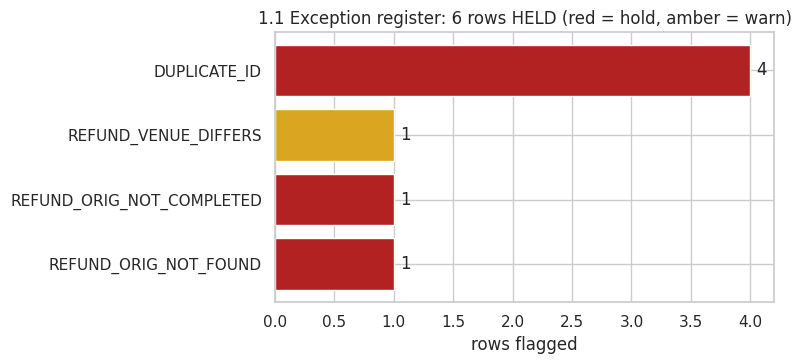

In [6]:
# Chart 1.1 — which controls fired
fl = summary[summary.rows_flagged > 0].reset_index(names="control").sort_values("rows_flagged")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(fl.control, fl.rows_flagged, color=fl.severity.map({"HOLD": "firebrick", "WARN": "goldenrod"}))
for i, v in enumerate(fl.rows_flagged): ax.text(v + .05, i, int(v), va="center")
ax.set_title(f"1.1 Exception register: {int(tx.hold.sum())} rows HELD (red = hold, amber = warn)")
ax.set_xlabel("rows flagged"); plt.tight_layout(); plt.show()

**What it shows.** Six rows are held: four rows that share two duplicated IDs (T00039, T00191), one refund (T02118) whose original sale is VOID, and one refund (T02119) pointing to a sale (T99999) that is not in the file. The amber bar is a warning (refund venue differs from the original) on one of the held rows.

**Why it matters.** Held rows earn and reverse nothing, but they stay visible for review. *Part 1 – exception register.*

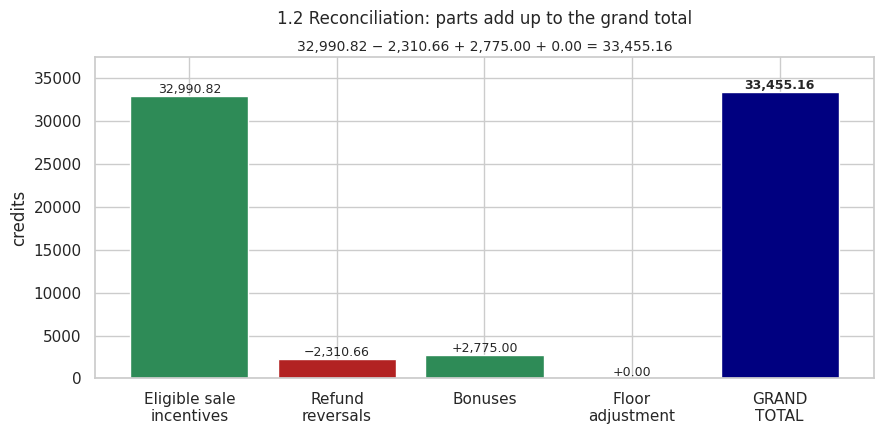

In [29]:
# Chart 1.2 — components vs grand total (all bars start at zero)
gross, rev = payout.eligible_sale_incentive.sum(), payout.refund_reversals.sum()
bon, total = payout.bonus.sum(), payout.final_payout.sum()

labels = ["Eligible sale\nincentives", "Refund\nreversals", "Bonuses", "Floor\nadjustment", "GRAND\nTOTAL"]
vals   = [gross, rev, bon, floor_adj, total]
text   = [f"{gross:,.2f}", f"−{rev:,.2f}", f"+{bon:,.2f}", f"{floor_adj:+,.2f}", f"{total:,.2f}"]
colors = ["seagreen", "firebrick", "seagreen", "gray", "navy"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(labels, vals, color=colors)
for i, (v, t) in enumerate(zip(vals, text)):
    ax.text(i, v + total * 0.01, t, ha="center", fontsize=9, fontweight="bold" if i == 4 else "normal")
ax.set_ylim(0, total * 1.12)
ax.set_ylabel("credits")
ax.set_title("1.2 Reconciliation: parts add up to the grand total", pad=24)
ax.text(0.5, 1.02, f"{gross:,.2f} − {rev:,.2f} + {bon:,.2f} + {floor_adj:,.2f} = {total:,.2f}",
        transform=ax.transAxes, ha="center", fontsize=10)
plt.tight_layout(); plt.show()

**What it shows.** Eligible incentives 32,990.82, minus reversals 2,310.66, plus bonuses 2,775.00 (37 × 75), plus a floor adjustment of 0.00, equals the grand total of **33,455.16**. The difference against the payout table is 0.00.

**Why it matters.** The grand total is rebuilt from its parts, as the brief requires. *Part 1 – reconciliation.*

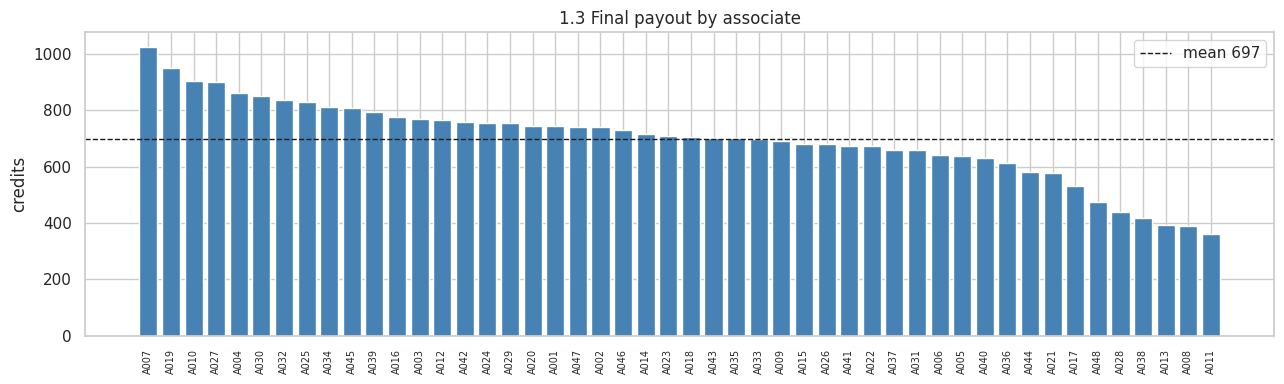

In [8]:
# Chart 1.3 — final payout per associate
pp = payout.final_payout.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(pp.index, pp.values, color="steelblue"); ax.axhline(pp.mean(), color="k", ls="--", lw=1, label=f"mean {pp.mean():,.0f}")
ax.set_title("1.3 Final payout by associate"); ax.set_ylabel("credits"); ax.tick_params(axis="x", rotation=90, labelsize=7); ax.legend()
plt.tight_layout(); plt.show()

**What it shows.** Final payout for each of the 48 associates. Mean 697.00; range 361.30 (A011) to 1,025.10 (A007). Nobody is paid below zero, so the max(0, ·) floor was never triggered.

**Why it matters.** Visual version of the payout table, so outliers are easy to spot. *Part 1 – payout table.*

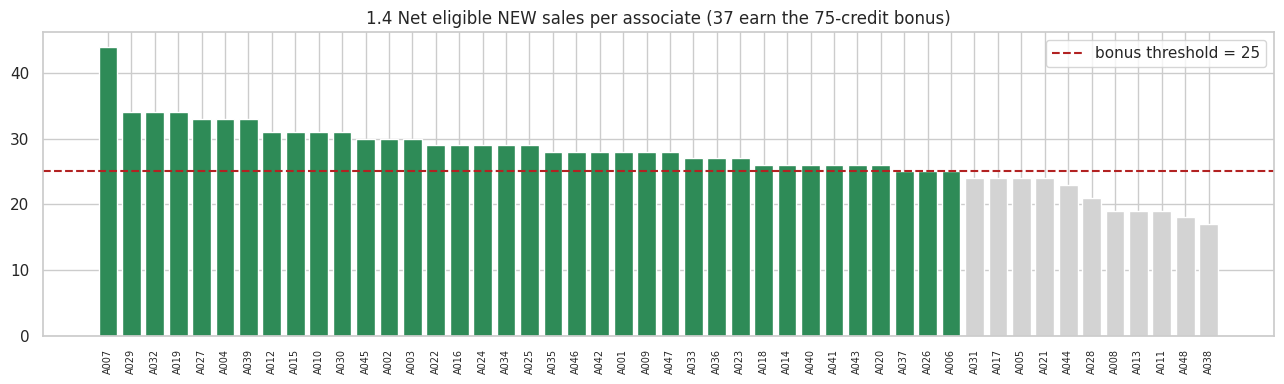

In [9]:
# Chart 1.4 — bonus rule: net NEW sales vs the 25 threshold
nn = payout.net_new_sales.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(nn.index, nn.values, color=np.where(nn.values >= BONUS_MIN_NEW, "seagreen", "lightgray"))
ax.axhline(BONUS_MIN_NEW, color="firebrick", ls="--", label=f"bonus threshold = {BONUS_MIN_NEW}")
ax.set_title(f"1.4 Net eligible NEW sales per associate ({int((payout.bonus>0).sum())} earn the {BONUS_AMOUNT}-credit bonus)")
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.legend(); plt.tight_layout(); plt.show()

**What it shows.** Net eligible NEW sales per associate (eligible NEW sales minus valid refunds of them). 37 associates reach the threshold of 25 and receive the 75-credit bonus; 11 do not, and 4 of those are exactly one sale short (24).

**Why it matters.** The bonus depends on the net count, so refunds can remove a bonus. *Part 1 – bonus rule.*

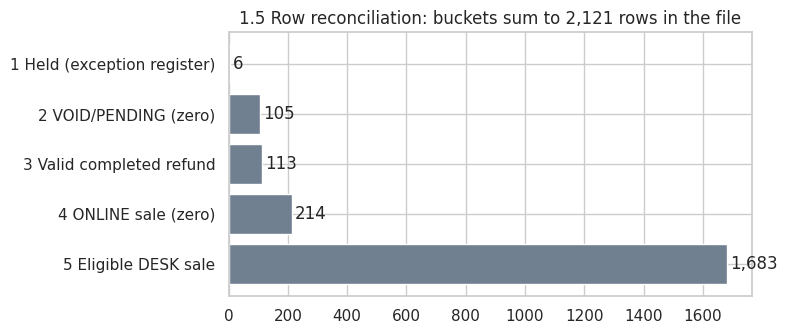

In [10]:
# Chart 1.5 — every row accounted for exactly once
rc_ = recon_c.drop(index="TOTAL rows in file")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(rc_.index[::-1], rc_.rows[::-1], color="slategray")
for i, v in enumerate(rc_.rows[::-1]): ax.text(v + 10, i, f"{v:,}", va="center")
ax.set_title(f"1.5 Row reconciliation: buckets sum to {len(tx):,} rows in the file"); plt.tight_layout(); plt.show()

**What it shows.** Every input row lands in exactly one bucket: 6 held + 105 VOID/PENDING + 113 valid completed refunds + 214 ONLINE sales (zero incentive) + 1,683 eligible DESK sales = **2,121 rows**, the size of the file.

**Why it matters.** Nothing is lost or counted twice. *Part 1 – reconciliation.*

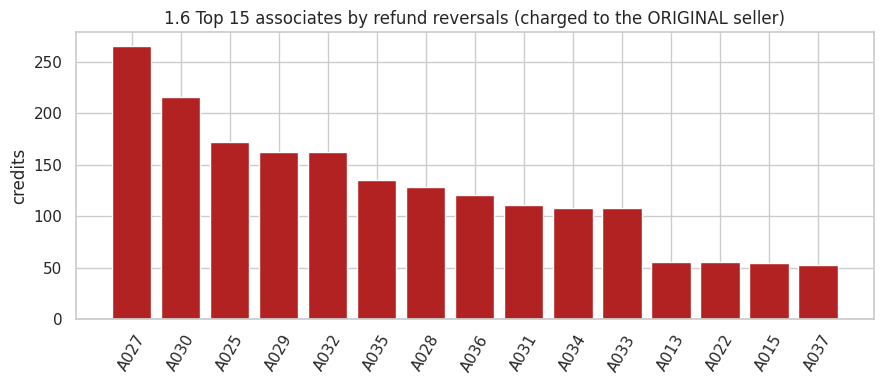

In [11]:
# Chart 1.6 — who bears the refund reversals
rv = payout.refund_reversals.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rv.index, rv.values, color="firebrick"); ax.tick_params(axis="x", rotation=60)
ax.set_title("1.6 Top 15 associates by refund reversals (charged to the ORIGINAL seller)"); ax.set_ylabel("credits")
plt.tight_layout(); plt.show()

**What it shows.** 35 associates carry at least one reversal; the largest are A027 (265.20), A030 (216.00) and A025 (171.60). All reversals add up to 2,310.66, matching the waterfall.

**Why it matters.** Reversals are charged to the **original seller**, not to whoever processed the refund. *Part 1 – refund rule.*

## 5. Export (summary page, payout, exceptions, reconciliation)

In [12]:
summary_page = pd.DataFrame({
    "Metric": ["Period", "Rows in file", "Rows held", "Eligible DESK sales", "Valid completed refunds",
               "Eligible sale incentives", "Refund reversals", "Bonuses (count × 75)", "Floor adjustment", "GRAND TOTAL PAYOUT"],
    "Value": [PERIOD, len(tx), int(tx.hold.sum()), int(calc.elig_sale.sum()), len(refunds_valid),
              round(payout.eligible_sale_incentive.sum(), 2), round(-payout.refund_reversals.sum(), 2),
              f"{payout.bonus.sum():,.0f} ({int((payout.bonus > 0).sum())} associates)", floor_adj, round(payout.final_payout.sum(), 2)]})
out_xlsx = OUT_DIR / f"payout_{PERIOD}.xlsx"
with pd.ExcelWriter(out_xlsx, engine="openpyxl") as xw:
    summary_page.to_excel(xw, sheet_name="Summary", index=False)
    payout.reset_index().to_excel(xw, sheet_name="Payout_by_associate", index=False)
    exceptions.to_excel(xw, sheet_name="Exception_register", index=False)
    recon_a.to_excel(xw, sheet_name="Reconciliation", index=False)
    recon_c.reset_index().to_excel(xw, sheet_name="Row_reconciliation", index=False)
    calc.drop(columns=["date_parsed"]).to_excel(xw, sheet_name="Calc_detail", index=False)
    for ws in xw.book.worksheets:
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(max(len(str(c.value or "")) for c in col) + 2, 40)
print("Saved", out_xlsx)
display(summary_page)

Saved outputs/payout_2026-06.xlsx


,Metric,Value
0,Period,2026-06
1,Rows in file,2121
2,Rows held,6
3,Eligible DESK sales,1683
4,Valid completed refunds,113
5,Eligible sale incentives,32990.82
6,Refund reversals,-2310.66
7,Bonuses (count × 75),"2,775 (37 associates)"
8,Floor adjustment,0.0
9,GRAND TOTAL PAYOUT,33455.16


## 5b. Repeatability evidence (20 pts)
**Refresh steps (also shown in chart 2.1):** (1) drop the new `museum_analyst_dataset.xlsx` next to the notebook · (2) edit `PERIOD` only if you do not want it inferred · (3) *Restart & Run All* · (4) read the exception register and the check dashboard · (5) pick up `outputs/payout_<period>.xlsx`.

The logic lives in three reusable functions — `prepare()`, `run_controls()`, `run_payout()` — and every control is vectorised, so nothing depends on row position or manual checking.

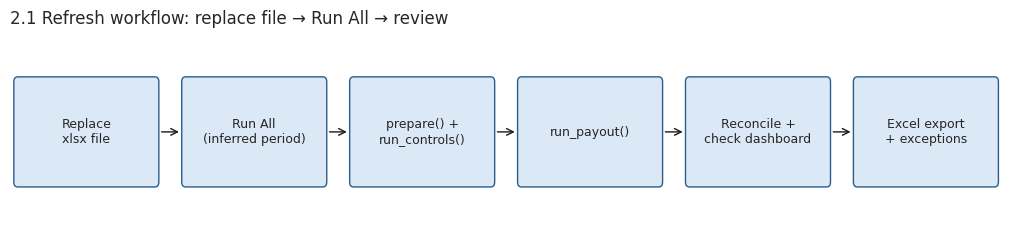

In [13]:
# Chart 2.1 — refresh workflow
from matplotlib.patches import FancyBboxPatch
steps_ = ["Replace\nxlsx file", "Run All\n(inferred period)", "prepare() +\nrun_controls()", "run_payout()", "Reconcile +\ncheck dashboard", "Excel export\n+ exceptions"]
fig, ax = plt.subplots(figsize=(13, 2.6)); ax.axis("off"); ax.set_xlim(0, len(steps_) * 2.2); ax.set_ylim(0, 2)
for i, t in enumerate(steps_):
    x = i * 2.2 + .1
    ax.add_patch(FancyBboxPatch((x, .5), 1.8, 1, boxstyle="round,pad=0.05", fc="#dbe9f6", ec="#2a5d8f"))
    ax.text(x + .9, 1, t, ha="center", va="center", fontsize=9)
    if i < len(steps_) - 1: ax.annotate("", xy=(x + 2.15, 1), xytext=(x + 1.85, 1), arrowprops=dict(arrowstyle="->", color="k"))
ax.set_title("2.1 Refresh workflow: replace file → Run All → review", loc="left"); plt.show()

**What it shows.** The refresh process: replace the file, Run All, controls, payout, reconciliation and checks, then Excel export.

**Why it matters.** Nothing is typed row by row and the period is inferred from the data. *Part 2 – refresh steps.*

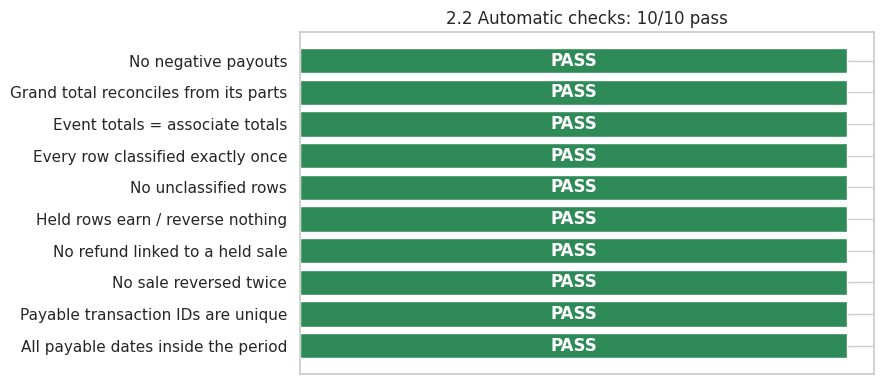

In [14]:
# Chart 2.2 — check dashboard (runs on the whole file)
checks = {
    "No negative payouts":                       bool((payout.final_payout >= 0).all()),
    "Grand total reconciles from its parts":     abs(recon_a.loc[6, "credits"]) < 0.005,
    "Event totals = associate totals":           abs(ev_sale - payout.eligible_sale_incentive.sum()) < 0.005 and abs(ev_rev - payout.refund_reversals.sum()) < 0.005,
    "Every row classified exactly once":         recon_c.loc["TOTAL rows in file", "rows"] == len(tx),
    "No unclassified rows":                      bool((calc.bucket != "9 Other / unclassified").all()),
    "Held rows earn / reverse nothing":          not bool((calc.hold & (calc.sale_incentive != 0)).any()),
    "No refund linked to a held sale":           not bool(calc[calc.hold].transaction_id.isin(refunds_valid.original_transaction_id).any()),
    "No sale reversed twice":                    bool(refunds_valid.original_transaction_id.is_unique),
    "Payable transaction IDs are unique":        bool(calc[~calc.hold].transaction_id.is_unique),
    "All payable dates inside the period":       bool((calc[~calc.hold].date_parsed.dt.strftime("%Y-%m") == PERIOD).all()),
}
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(list(checks)[::-1], [1] * len(checks), color=["seagreen" if v else "firebrick" for v in list(checks.values())[::-1]])
for i, v in enumerate(list(checks.values())[::-1]): ax.text(.5, i, "PASS" if v else "FAIL", ha="center", va="center", color="white", fontweight="bold")
ax.set_xticks([]); ax.set_title(f"2.2 Automatic checks: {sum(checks.values())}/{len(checks)} pass"); plt.tight_layout(); plt.show()

**What it shows.** Ten automatic checks run on the whole file after every run (no negative payouts, totals tie, each row classified once, held rows pay nothing, no double reversal, unique payable IDs, dates inside the period). All 10 pass.

**Why it matters.** On next month's file any failure turns red immediately. *Part 2 – checks across the full file.*

,injected fault,expected flag,caught
0,Blank required field,MISSING_FIELD,True
1,Unexpected category,UNEXPECTED_CATEGORY,True
2,Date outside period,BAD_DATE,True
3,Negative amount,BAD_AMOUNT,True
4,Price off the price list,PRICE_MISMATCH,True
5,Refund amount mismatch,REFUND_AMOUNT_MISMATCH,True
6,Refund product mismatch,REFUND_PRODUCT_MISMATCH,True
7,Refund to unknown sale,REFUND_ORIG_NOT_FOUND,True
8,Duplicate transaction ID (new copy),DUPLICATE_ID,True


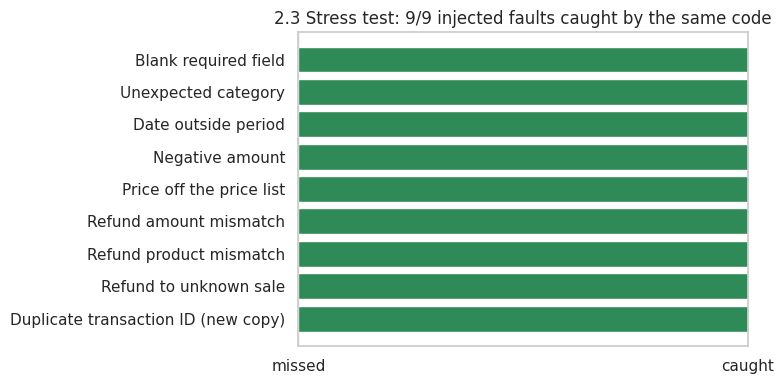

In [15]:
# Chart 2.3 — fault-injection stress test: do the controls catch problems on a modified copy of the file?
t = raw.copy()
sale_ids  = t.index[(t.event_type == "SALE") & (t.status == "COMPLETED") & (t.channel == "DESK")]
ref_ids   = t.index[(t.event_type == "REFUND") & (t.status == "COMPLETED")]
tests = {}
t.loc[sale_ids[200], "product"] = np.nan;                tests["Blank required field"]        = (sale_ids[200], "MISSING_FIELD")
t.loc[sale_ids[210], "channel"] = "KIOSK";               tests["Unexpected category"]         = (sale_ids[210], "UNEXPECTED_CATEGORY")
t.loc[sale_ids[220], "date"] = "2026-07-03";             tests["Date outside period"]         = (sale_ids[220], "BAD_DATE")
t.loc[sale_ids[230], "amount_credits"] = "-50";          tests["Negative amount"]             = (sale_ids[230], "BAD_AMOUNT")
t.loc[sale_ids[240], "amount_credits"] = "199";          tests["Price off the price list"]    = (sale_ids[240], "PRICE_MISMATCH")
t.loc[ref_ids[10], "amount_credits"] = "999";            tests["Refund amount mismatch"]      = (ref_ids[10], "REFUND_AMOUNT_MISMATCH")
t.loc[ref_ids[20], "product"] = "Circle" if t.loc[ref_ids[20], "product"] != "Circle" else "Single"
tests["Refund product mismatch"] = (ref_ids[20], "REFUND_PRODUCT_MISMATCH")
t.loc[ref_ids[30], "original_transaction_id"] = "T77777"; tests["Refund to unknown sale"]      = (ref_ids[30], "REFUND_ORIG_NOT_FOUND")
dup = t.loc[[sale_ids[300]]]; t = pd.concat([t, dup], ignore_index=True)
tests["Duplicate transaction ID (new copy)"] = (len(t) - 1, "DUPLICATE_ID")

_, HOLD_t, _ = run_controls(prepare(t))
res = pd.DataFrame([{"injected fault": k, "expected flag": r, "caught": bool(HOLD_t.loc[i, r])} for k, (i, r) in tests.items()])
display(res)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(res["injected fault"][::-1], res.caught[::-1].astype(int), color=["seagreen" if c else "firebrick" for c in res.caught[::-1]])
ax.set_xlim(0, 1); ax.set_xticks([0, 1]); ax.set_xticklabels(["missed", "caught"])
ax.set_title(f"2.3 Stress test: {int(res.caught.sum())}/{len(res)} injected faults caught by the same code"); plt.tight_layout(); plt.show()

**What it shows.** Nine deliberate errors were injected into a copy of the file (blank field, bad category, date outside the month, negative amount, off-list price, refund amount mismatch, refund product mismatch, refund to an unknown sale, duplicate ID). The same functions caught all 9.

**Why it matters.** The controls are generic, not tuned to this month's six exceptions. *Part 2 – repeatability.*

## 6. Investigation — find the largest concentration of refunds
Method: for every *venue × offer × product* cell with at least `MIN_N` payable sales, compute the share of sales later refunded. The most extreme cell is investigated (it is selected by the data, so this also works next month).

In [16]:
base = calc[calc.event_type.eq("SALE") & calc.status.eq("COMPLETED") & ~calc.hold].copy()
base["offer"] = base.offer_code.fillna("NONE")
base["refunded"] = base.transaction_id.isin(refunds_valid.original_transaction_id)

grid = (base.groupby(["venue", "offer", "product"])
        .agg(sales=("transaction_id", "size"), refunded=("refunded", "sum"), credits=("amount_num", "sum"))
        .assign(refund_rate=lambda g: (g.refunded / g.sales).round(3)))
rank = grid[grid.sales >= MIN_N].sort_values("refund_rate", ascending=False)
display(rank.head(8))

HV, HO, HP = rank.index[0]
print(f"Flagged cell → venue={HV} | offer={HO} | product={HP}")

sales  refunded  credits  refund_rate
venue         offer          product                                       
Garden Wing   MIDYEAR-CIRCLE Circle      76        57    17100        0.750
River Annex   NONE           Single     119         9    14280        0.076
Garden Wing   NONE           Single     124         7    14880        0.056
Clock Hall    NONE           Single     129         6    15480        0.047
River Annex   NONE           Circle     140         6    42000        0.043
Garden Wing   NONE           Duo        121         5    24200        0.041
              OPEN-DAY       Duo         29         1     4590        0.034
North Gallery OPEN-DAY       Circle      29         1     6975        0.034

Flagged cell → venue=Garden Wing | offer=MIDYEAR-CIRCLE | product=Circle


In [17]:
cohort = base[(base.venue == HV) & (base.offer == HO)]
rest   = base.drop(cohort.index)
d0, d1 = cohort.date.min(), cohort.date.max()
print(f"Cohort window: {d0} → {d1}")

# 6a. sales surge vs baseline, in context of admissions
vsales = base.groupby(["venue", "date"]).size().rename("sales").reset_index().merge(adm, on=["venue", "date"], how="left")
in_win = vsales.date.between(d0, d1)
ctx = (vsales.assign(window=np.where(in_win, "in window", "baseline"))
       .groupby(["venue", "window"]).agg(avg_daily_sales=("sales", "mean"), avg_admissions=("admissions", "mean")).round(1)
       .unstack("window"))
display(ctx)

# 6b. refund rate cohort vs everything else
n_c, r_c = len(cohort), int(cohort.refunded.sum())
n_r, r_r = len(rest), int(rest.refunded.sum())
print(f"Cohort refund rate: {r_c}/{n_c} = {r_c/n_c:.1%} | rest of file: {r_r}/{n_r} = {r_r/n_r:.1%} "
      f"| cohort = {r_c/(r_c+r_r):.0%} of all refunds, {n_c/(n_c+n_r):.1%} of sales")

# 6c. who, when
rc = refunds_valid[refunds_valid.original_transaction_id.isin(cohort.transaction_id)].copy()
rc["lag_days"] = (pd.to_datetime(rc.date) - pd.to_datetime(cohort.set_index("transaction_id").loc[rc.original_transaction_id, "date"].values)).dt.days
print("Refund lag (days since sale):", rc.lag_days.describe().round(1).to_dict())
print("Refund dates:", rc.date.min(), "→", rc.date.max())
print("Top sellers share of cohort sales:", (cohort.associate_id.value_counts(normalize=True).head(5).round(3)).to_dict())
print("Top refund processors share:      ", (rc.processed_by.value_counts(normalize=True).head(5).round(3)).to_dict())

# 6d. incentive impact (actual vs counterfactual without the cohort and its refunds)
gross_inc = cohort[cohort.elig_sale].sale_incentive.sum()
rev_inc   = rc.reversal.sum()
cf = tx[~tx.transaction_id.isin(cohort.transaction_id) & ~tx.original_transaction_id.isin(cohort.transaction_id)]
_, _, payout_cf = run_payout(cf)
cmp_ = payout[["bonus", "final_payout"]].join(payout_cf[["bonus", "final_payout"]], rsuffix="_ex_cohort").fillna(0)
print(f"Cohort gross incentive {gross_inc:,.2f} | reversed {rev_inc:,.2f} | net kept {gross_inc-rev_inc:,.2f}")
print(f"Total payout actual {payout.final_payout.sum():,.2f} vs ex-cohort {payout_cf.final_payout.sum():,.2f} "
      f"| bonuses actual {int((payout.bonus>0).sum())} vs ex-cohort {int((payout_cf.bonus>0).sum())}")
chg = cmp_[cmp_.bonus != cmp_.bonus_ex_cohort]
print("Associates whose bonus status depends on the cohort:", list(chg.index))

Cohort window: 2026-06-18 → 2026-06-21


avg_daily_sales           avg_admissions          
window               baseline in window       baseline in window
venue                                                           
Clock Hall               15.0      15.8          557.2     556.8
Garden Wing              15.0      34.2          464.6     433.8
North Gallery            15.5      17.8          633.0     609.8
River Annex              14.9      13.8          518.4     513.2

Cohort refund rate: 57/76 = 75.0% | rest of file: 56/1821 = 3.1% | cohort = 50% of all refunds, 4.0% of sales
Refund lag (days since sale): {'count': 57.0, 'mean': 7.1, 'std': 1.5, 'min': 4.0, '25%': 6.0, '50%': 7.0, '75%': 8.0, 'max': 10.0}
Refund dates: 2026-06-24 → 2026-06-28
Top sellers share of cohort sales: {'A029': 0.118, 'A030': 0.118, 'A035': 0.105, 'A027': 0.105, 'A034': 0.105}
Top refund processors share:       {'A033': 0.14, 'A025': 0.105, 'A026': 0.105, 'A030': 0.105, 'A035': 0.088}
Cohort gross incentive 2,052.00 | reversed 1,539.00 | net kept 513.00
Total payout actual 33,455.16 vs ex-cohort 32,942.16 | bonuses actual 37 vs ex-cohort 37
Associates whose bonus status depends on the cohort: []


### Part 3 visuals (Investigation — 30 pts), one chart per cell

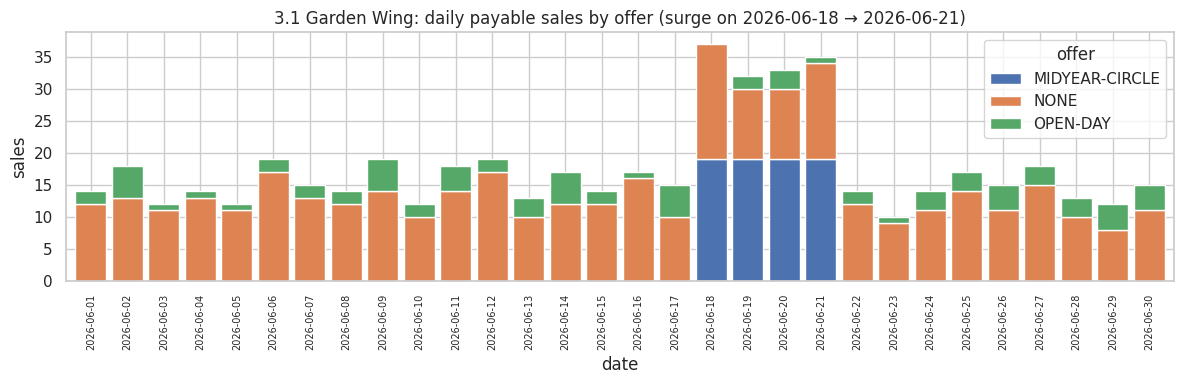

In [18]:
# Chart 3.1 — the surge: daily payable sales at the flagged venue, split by offer
dd = base[base.venue == HV].groupby(["date", "offer"]).size().unstack(fill_value=0)
ax = dd.plot(kind="bar", stacked=True, figsize=(12, 4), width=.85)
ax.set_title(f"3.1 {HV}: daily payable sales by offer (surge on {d0} → {d1})"); ax.set_ylabel("sales")
ax.tick_params(axis="x", labelsize=7, rotation=90); plt.tight_layout(); plt.show()

**What it shows.** Garden Wing daily sales split by offer. MIDYEAR-CIRCLE appears only on 18–21 June (19 sales a day) and lifts the venue from about 15 sales a day to 34.2 inside the window.

**Why it matters.** This is the material change selected by the data. *Part 3 – the concentration.*

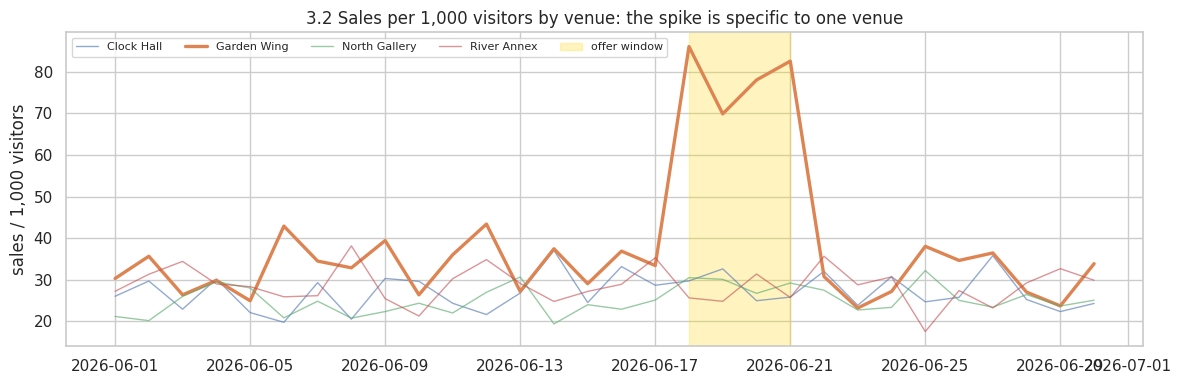

In [19]:
# Chart 3.2 — not explained by footfall: sales per 1,000 visitors, all venues
vs = vsales.assign(per_1000=vsales.sales / vsales.admissions * 1000)
fig, ax = plt.subplots(figsize=(12, 4))
for v, g in vs.groupby("venue"):
    g = g.sort_values("date"); ax.plot(pd.to_datetime(g.date), g.per_1000, label=v, lw=2.4 if v == HV else 1, alpha=1 if v == HV else .6)
ax.axvspan(pd.to_datetime(d0), pd.to_datetime(d1), color="gold", alpha=.25, label="offer window")
ax.set_title("3.2 Sales per 1,000 visitors by venue: the spike is specific to one venue"); ax.set_ylabel("sales / 1,000 visitors"); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

**What it shows.** Sales per 1,000 visitors (using the Admissions sheet). Garden Wing averages 79.1 inside the window versus 32.4 outside, peaking at 86; the other venues stay roughly between 25 and 29. Admissions did not rise (465 → 434 a day).

**Why it matters.** Footfall does not explain the surge, and it is specific to one venue. *Part 3 – context.*

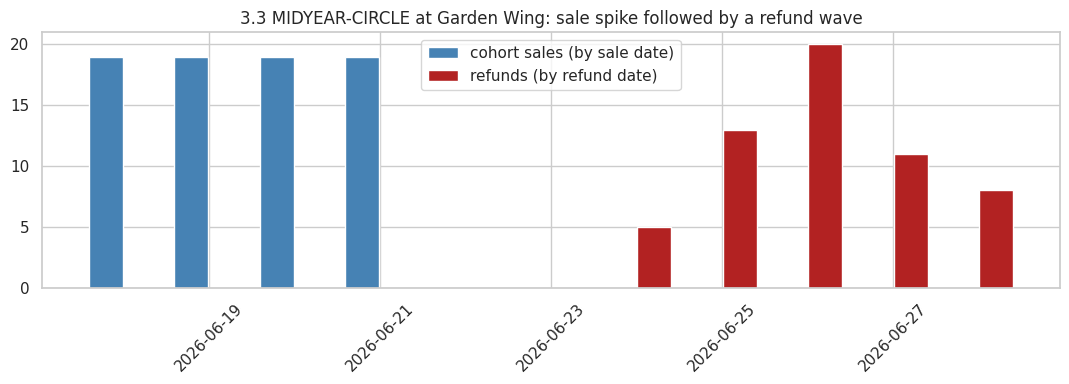

In [20]:
# Chart 3.3 — cohort timeline: when sold vs when refunded
ts = cohort.groupby("date").size(); tr = rc.groupby("date").size()
tl = pd.concat([ts.rename("sold"), tr.rename("refunded")], axis=1).fillna(0)
tl.index = pd.to_datetime(tl.index); tl = tl.sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(tl.index - pd.Timedelta(hours=5), tl.sold, width=.4, color="steelblue", label="cohort sales (by sale date)")
ax.bar(tl.index + pd.Timedelta(hours=5), tl.refunded, width=.4, color="firebrick", label="refunds (by refund date)")
ax.set_title(f"3.3 {HO} at {HV}: sale spike followed by a refund wave"); ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**What it shows.** 19 cohort sales on each of 18–21 June, then no refunds until 24 June, followed by 57 refunds between 24 and 28 June (5, 13, 20, 11, 8), peaking on 26 June.

**Why it matters.** A sale spike followed by a refund wave in the same cohort. *Part 3 – what the data establishes.*

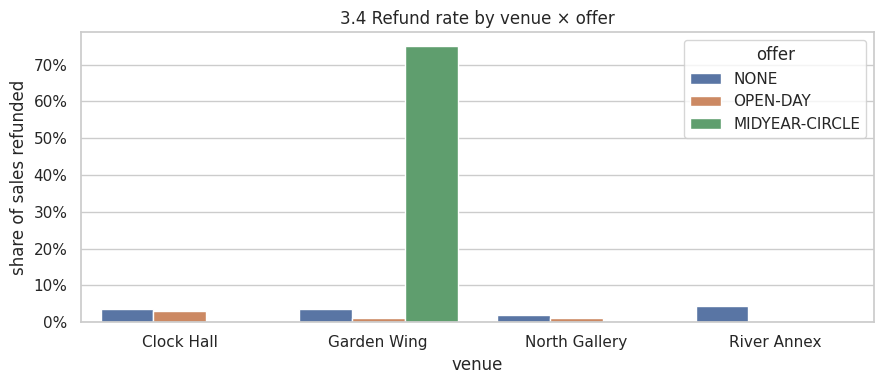

In [21]:
# Chart 3.4 — refund rate by venue x offer
rr = base.groupby(["venue", "offer"]).agg(rate=("refunded", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=rr, x="venue", y="rate", hue="offer", ax=ax)
ax.set_title("3.4 Refund rate by venue × offer"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylabel("share of sales refunded")
plt.tight_layout(); plt.show()

**What it shows.** Refund rate by venue and offer. MIDYEAR-CIRCLE at Garden Wing is 75.0%; every other combination is between 0% and 4.5%.

**Why it matters.** Quantifies the concentration: 57 of 76 sales refunded versus 3.1% elsewhere. *Part 3 – quantification.*

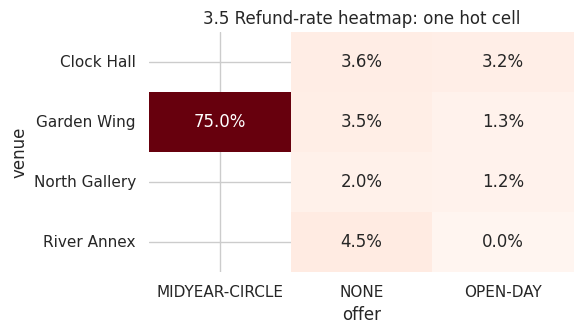

In [22]:
# Chart 3.5 — heatmap view of the same concentration
hm = base.pivot_table(index="venue", columns="offer", values="refunded", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.heatmap(hm, annot=True, fmt=".1%", cmap="Reds", cbar=False, ax=ax); ax.set_title("3.5 Refund-rate heatmap: one hot cell"); plt.tight_layout(); plt.show()

**What it shows.** The same rates as a heatmap: one hot cell. Garden Wing's other offers sit at 3.5% (no offer) and 1.3% (OPEN-DAY).

**Why it matters.** The problem is the offer at this venue, not Garden Wing in general and not the whole group. *Part 3 – what the data establishes.*

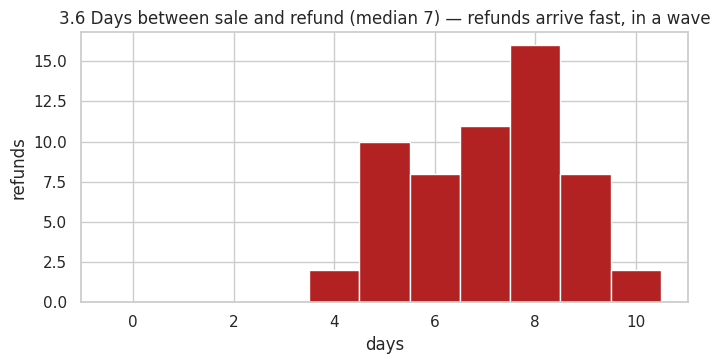

In [23]:
# Chart 3.6 — refund lag
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(rc.lag_days, bins=range(0, int(rc.lag_days.max()) + 2), color="firebrick", edgecolor="white", align="left")
ax.set_title(f"3.6 Days between sale and refund (median {rc.lag_days.median():.0f}) — refunds arrive fast, in a wave"); ax.set_xlabel("days"); ax.set_ylabel("refunds")
plt.tight_layout(); plt.show()

**What it shows.** Days between sale and refund: median 7, range 4 to 10.

**Why it matters.** Refunds arrive together shortly after the sale window, a wave rather than a slow trickle. This supports the distinguishing check in the note. *Part 3.*

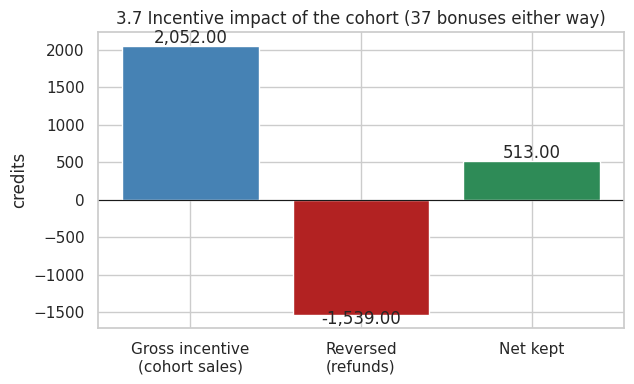

In [24]:
# Chart 3.7 — incentive impact
fig, ax = plt.subplots(figsize=(6.5, 4))
vals = [gross_inc, -rev_inc, gross_inc - rev_inc]
ax.bar(["Gross incentive\n(cohort sales)", "Reversed\n(refunds)", "Net kept"], vals, color=["steelblue", "firebrick", "seagreen"])
for i, v in enumerate(vals): ax.text(i, v + (40 if v >= 0 else -120), f"{v:,.2f}", ha="center")
ax.axhline(0, color="k", lw=.8); ax.set_title(f"3.7 Incentive impact of the cohort ({int(cmp_.bonus.gt(0).sum())} bonuses either way)"); ax.set_ylabel("credits")
plt.tight_layout(); plt.show()

**What it shows.** Gross incentive on the cohort 2,052.00 (76 × 27.00), reversed 1,539.00 (57 × 27.00), net kept 513.00. Total payout is 33,455.16 with the cohort and 32,942.16 without it; no associate's bonus changes.

**Why it matters.** The incentive impact the brief asks for. *Part 3 – incentive impact.*

### Investigation note (June 2026 run)
**Finding.** Garden Wing sold **76 MIDYEAR-CIRCLE** memberships (Circle at 225 instead of 300; all DESK/NEW) on **18–21 June**. Its daily payable sales jumped from 15.0 to 34.2 while admissions slipped (465 → 434/day), so footfall does not explain it. **57 of the 76 (75%) were refunded**, all processed 24–28 June, versus 3.1% for every other sale. The cohort is 4% of sales but 50% of all refunds.

**Incentive impact.** The cohort earned 2,052.00 (76 × 27.00); refunds reverse 1,539.00 from the original sellers, leaving 513.00. Payout is 33,455.16 with the cohort and 32,942.16 without it. No associate's bonus depends on it. The 19 unrefunded sales (513.00) stay exposed to July refunds, which will be held because their originals will not be in the July file.

**What the data establishes.** The spike, the refund wave and its concentration in one offer at one venue. Sellers and refund processors are spread out, so no single person drives it. It does not establish *why* buyers refunded.

**Two plausible causes.** (1) The offer was mis-sold or misunderstood, or a pricing error occurred. (2) Sell-and-refund gaming for the 12% Circle rate and the bonus count.

**Distinguishing check.** Review refund reason codes and member IDs for the 57 refunds: price/terms reasons from distinct buyers point to cause 1; repeat or linked members, or memberships never used, point to cause 2.

## 7. Final self-checks

In [25]:
assert (payout.final_payout >= 0).all(), "negative payout"
assert abs(recon_a.loc[6, "credits"]) < 0.005, "grand total does not reconcile"
assert recon_c.loc["TOTAL rows in file", "rows"] == len(tx), "row buckets do not cover the file"
assert not (calc.hold & (calc.sale_incentive != 0)).any(), "held row earned incentive"
assert not calc[calc.hold].transaction_id.isin(refunds_valid.original_transaction_id).any(), "refund linked to held sale"
assert refunds_valid.original_transaction_id.is_unique, "a sale was reversed twice"
assert (calc.bucket != "9 Other / unclassified").all(), "unclassified rows"
print("All checks passed. Grand total payout =", f"{payout.final_payout.sum():,.2f}")

All checks passed. Grand total payout = 33,455.16


## 8. Final summary table (mapped to the PDF rubric)
One page for the evaluator: payout, reconciliation, controls, repeatability and investigation.

In [27]:
final_summary = pd.DataFrame([
    ["Period", PERIOD],
    ["Rows in file / rows held", f"{len(tx):,} / {int(tx.hold.sum())}"],
    ["Eligible DESK sales / valid completed refunds", f"{int(calc.elig_sale.sum()):,} / {len(refunds_valid)}"],
    ["Eligible sale incentives", f"{payout.eligible_sale_incentive.sum():,.2f}"],
    ["– Refund reversals", f"{payout.refund_reversals.sum():,.2f}"],
    [f"+ Bonuses ({int((payout.bonus > 0).sum())} associates × {BONUS_AMOUNT})", f"{payout.bonus.sum():,.2f}"],
    ["+ Floor adjustment (max(0, ·))", f"{floor_adj:,.2f}"],
    ["GRAND TOTAL PAYOUT", f"{payout.final_payout.sum():,.2f}"],
    ["Reconciliation difference (parts vs total)", f"{recon_a.loc[6, 'credits']:.2f}"],
    ["Automatic checks passed", f"{sum(checks.values())}/{len(checks)}"],
    ["Stress test: injected faults caught", f"{int(res.caught.sum())}/{len(res)}"],
    ["Investigation: concentration", f"{HV} / {HO}: {r_c}/{n_c} refunded ({r_c/n_c:.0%}) vs {r_r/n_r:.1%} elsewhere"],
    ["Investigation: incentive impact", f"gross {gross_inc:,.2f}, reversed {rev_inc:,.2f}, net {gross_inc-rev_inc:,.2f}"],
], columns=["Item", "Value"])
display(final_summary)

with pd.ExcelWriter(out_xlsx, mode="a", engine="openpyxl", if_sheet_exists="replace") as xw:
    final_summary.to_excel(xw, sheet_name="Final_summary", index=False)
    ws = xw.book["Final_summary"]
    for col in ws.columns:
        ws.column_dimensions[col[0].column_letter].width = min(max(len(str(c.value or "")) for c in col) + 2, 90)
print("Final summary also saved to", out_xlsx)

,Item,Value
0,Period,2026-06
1,Rows in file / rows held,"2,121 / 6"
2,Eligible DESK sales / valid completed refunds,"1,683 / 113"
3,Eligible sale incentives,"32,990.82"
4,– Refund reversals,"2,310.66"
5,+ Bonuses (37 associates × 75),"2,775.00"
6,"+ Floor adjustment (max(0, ·))",0.00
7,GRAND TOTAL PAYOUT,"33,455.16"
8,Reconciliation difference (parts vs total),0.00
9,Automatic checks passed,10/10


Final summary also saved to outputs/payout_2026-06.xlsx
